# Binary Image Classification with a Convolutional Neural Network

This offline-first tutorial trains a small CNN on deterministic synthetic cat-like and dog-like textures. The fixture keeps preprocessing, convolution, validation, evaluation, and prediction executable without downloading a dataset. Replace the fixture arrays with licensed real images for a production experiment.

In [1]:
import os, random
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import train_test_split

SEED = 200
os.environ['TF_DETERMINISTIC_OPS'] = '1'
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
OUTPUT_DIR = Path('generated/cv-200'); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('TensorFlow', tf.__version__, '| GPU devices:', len(tf.config.list_physical_devices('GPU')))

TensorFlow 2.21.0 | GPU devices: 0


## 1. Create a Deterministic Image Fixture

Class 0 contains diagonal, warm textures; class 1 contains vertical, cool textures. Noise and small shifts prevent the task from being a single-pixel lookup.

In [2]:
def make_fixture(samples_per_class=96, size=32):
    rng = np.random.default_rng(SEED); images=[]; labels=[]
    yy, xx = np.mgrid[:size, :size]
    for label in (0, 1):
        for _ in range(samples_per_class):
            shift = rng.integers(-3, 4)
            pattern = np.sin((xx + yy + shift) / 2.5) if label == 0 else np.sin((xx + shift) / 2.0)
            base = np.zeros((size, size, 3), dtype=np.float32)
            base[..., label * 2] = 0.55 + 0.25 * pattern
            base[..., 1] = 0.25 + 0.12 * pattern
            images.append(np.clip(base + rng.normal(0, 0.08, base.shape), 0, 1)); labels.append(label)
    return np.asarray(images), np.asarray(labels)

images, labels = make_fixture()
X_train, X_valid, y_train, y_valid = train_test_split(images, labels, test_size=.25, stratify=labels, random_state=SEED)
print('train:', X_train.shape, 'validation:', X_valid.shape)

train: (144, 32, 32, 3) validation: (48, 32, 32, 3)


## 2. Define and Train a Modern Keras CNN

In [3]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.RandomFlip('horizontal', seed=SEED),
    tf.keras.layers.Conv2D(12, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(24, 3, activation='relu'),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(.15, seed=SEED),
    tf.keras.layers.Dense(1, activation='sigmoid')])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, validation_data=(X_valid, y_valid), epochs=5, batch_size=24, verbose=0)
probabilities = model.predict(X_valid, verbose=0).ravel(); predictions = (probabilities >= .5).astype(int)
print(f'validation accuracy: {accuracy_score(y_valid, predictions):.3f}')

validation accuracy: 1.000


## 3. Evaluate Training and Predictions

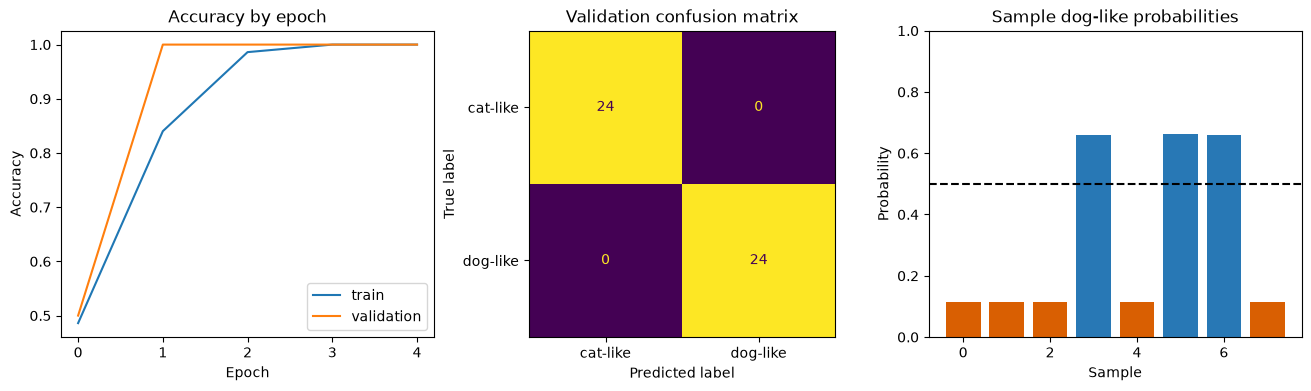

saved: generated\cv-200\synthetic-cnn-evaluation.png


In [4]:
figure, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
axes[0].plot(history.history['accuracy'], label='train'); axes[0].plot(history.history['val_accuracy'], label='validation')
axes[0].set(title='Accuracy by epoch', xlabel='Epoch', ylabel='Accuracy'); axes[0].legend()
ConfusionMatrixDisplay.from_predictions(y_valid, predictions, display_labels=['cat-like', 'dog-like'], colorbar=False, ax=axes[1])
axes[1].set_title('Validation confusion matrix')
sample_ids = np.arange(8); axes[2].bar(sample_ids, probabilities[:8], color=np.where(predictions[:8], '#2878b5', '#d95f02'))
axes[2].axhline(.5, color='black', linestyle='--'); axes[2].set(title='Sample dog-like probabilities', xlabel='Sample', ylabel='Probability', ylim=(0, 1))
figure_path = OUTPUT_DIR / 'synthetic-cnn-evaluation.png'; figure.savefig(figure_path, dpi=170, bbox_inches='tight'); plt.show()
print('saved:', figure_path)